# FINAL YEAR PROJECT

# GPT Models for Time-series Analysis and Forecasting.

**Experiment 2 - Energy mix dataset (Cyprus, hourly).** Same pipeline as the traffic-camera notebook, applied to a different type of data: a long, regular, strongly seasonal hourly series.

<hr>

In [1]:
import autogluon
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import time
import timesfm
import torch

from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor # Chronos

from catboost import CatBoostRegressor

from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from statsmodels.tsa.arima.model import ARIMA

from tirex import load_model, ForecastModel

```
!pip uninstall torch torchvision torchaudio -y
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

**TimesFM Installation**

```
!pip install timesfm[torch]
!pip install -U huggingface_hub
```

**AutoGluon installation**

```
!pip install autogluon.timeseries
```

<hr>

## Data

Hourly **electricity generation mix of Cyprus**, estimated from **2022-01-01 to 2024-05-30**. <br>
Columns: `total`, and generation of the sources: `wind`, `oil`, `gas`, `coal`, `biomass`, `pv`, `water`.

Difference from the traffic data used in the first experiment:

| | Traffic (car count) | Energy mix |
|---|---|---|
| Frequency | 1 second | 1 hour |
| Length | ~2 hours (7.2k points) | ~2.4 years (21k points) |
| Seasonality | none | strong daily + weekly + yearly |
| Test set | last 60 seconds | last 168 hours (1 week) |

In [2]:
df = pd.read_csv("EnergyMix_CY_historical_estimated_01-01-2022_30-05-2024.csv")

In [3]:
display(df.head(5))

,timestamp,total,wind,oil,gas,coal,biomass,pv,water
0,2022-01-01 00:00:00+02:00,556.0,78.0,471.0,0,0,6.0,0.0,0
1,2022-01-01 01:00:00+02:00,517.0,70.0,441.0,0,0,6.0,0.0,0
2,2022-01-01 02:00:00+02:00,479.0,57.0,416.0,0,0,6.0,0.0,0
3,2022-01-01 03:00:00+02:00,433.0,40.0,387.0,0,0,6.0,0.0,0
4,2022-01-01 04:00:00+02:00,404.0,45.0,353.0,0,0,6.0,0.0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21119 entries, 0 to 21118
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  21119 non-null  object 
 1   total      21119 non-null  float64
 2   wind       21119 non-null  float64
 3   oil        21119 non-null  float64
 4   gas        21119 non-null  int64  
 5   coal       21119 non-null  int64  
 6   biomass    21119 non-null  float64
 7   pv         21119 non-null  float64
 8   water      21119 non-null  int64  
dtypes: float64(5), int64(3), object(1)
memory usage: 1.5+ MB


<hr>

### Data quality

Timestamps carry a UTC offset (`+02:00` in winter, `+03:00` in summer), so they are parsed as UTC. Checking for duplicates and missing hours: the models need a **regular** hourly grid.

In [5]:
# to_datetime
df["dt"] = pd.to_datetime(df["timestamp"], utc=True)

In [6]:
# count of duplicates & date range
print("duplicated timestamps:", df["dt"].duplicated().sum())
print("date range:", df["dt"].min(), "-", df["dt"].max())

duplicated timestamps: 0
date range: 2021-12-31 22:00:00+00:00 - 2024-05-30 20:00:00+00:00


In [7]:
# count of missing hours
full_index = pd.date_range(df["dt"].min(), df["dt"].max(), freq="h")
missing = full_index.difference(df["dt"])
print("expected hours:", len(full_index), ", present:", len(df), ", missing:", len(missing))

expected hours: 21143 , present: 21119 , missing: 24


In [8]:
# group consecutive missing hours into gaps
m = pd.Series(missing)
gap_id = m.diff().ne(pd.Timedelta("1h")).cumsum()
gaps = m.groupby(gap_id).agg(start="min", end="max", hours="count")
gaps[["start", "end"]] = gaps[["start", "end"]].apply(lambda s: s.dt.tz_convert("Asia/Nicosia"))
display(gaps)

,start,end,hours
1,2022-01-02 22:00:00+02:00,2022-01-02 23:00:00+02:00,2
2,2022-01-06 18:00:00+02:00,2022-01-07 00:00:00+02:00,7
3,2022-07-27 15:00:00+03:00,2022-07-27 23:00:00+03:00,9
4,2022-10-30 03:00:00+03:00,2022-10-30 03:00:00+02:00,2
5,2022-11-05 00:00:00+02:00,2022-11-05 00:00:00+02:00,1
6,2023-05-23 12:00:00+03:00,2023-05-23 12:00:00+03:00,1
7,2023-10-29 03:00:00+03:00,2023-10-29 03:00:00+02:00,2


In [9]:
df = df.drop_duplicates("dt").set_index("dt").sort_index()
df = df.reindex(full_index) # missing hours become NaN rows
df = df.interpolate(method="time", limit=12) # fill gaps (longest is 9 h)

C:\Users\whois\AppData\Local\Temp\ipykernel_21264\3825613970.py:3: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df = df.interpolate(method="time", limit=12) # fill gaps (longest is 9 h)


### Energy sources

* Cyprus doesn't use `[gas, coal, water]` as energy sources as `share_of_zero_hours_%` suggests, since it's meaning is "how often this energy source produces nothing, by hour"
* We can see that `PV` (solar) energy source is 51.2% of the time produces 0 energy, its logically correct because it is 0 at night.
* `biomass` is reported as a constant 6 MW for all 21,143 hours (one unique value, 1% of the mix), so it has zero variance and no temporal structure. It carries no information for forecasting and will be excluded. The same applies to `gas`, `coal` and `water` (always 0).
* The mix is practically **oil (81%) + PV (14%) + wind (4%)**.

In [10]:
sources = ["oil", "wind", "pv", "biomass", "gas", "coal", "water"]
hourly = df

In [11]:
# descriptive stat
mix = pd.DataFrame({
    "mean": hourly[sources].mean(),
    "share_%": hourly[sources].mean() / hourly["total"].mean() * 100,
    "share_of_zero_hours_%": (hourly[sources] == 0).mean() * 100,
    "unique_values": hourly[sources].nunique(),
    }).round(1)

display(mix)

,mean,share_%,share_of_zero_hours_%,unique_values
oil,472.9,80.6,0.0,793
wind,24.5,4.2,7.3,161
pv,81.7,13.9,51.2,437
biomass,6.0,1.0,0.0,1
gas,0.0,0.0,100.0,1
coal,0.0,0.0,100.0,1
water,0.0,0.0,100.0,1


<hr>

### Exploratory analysis

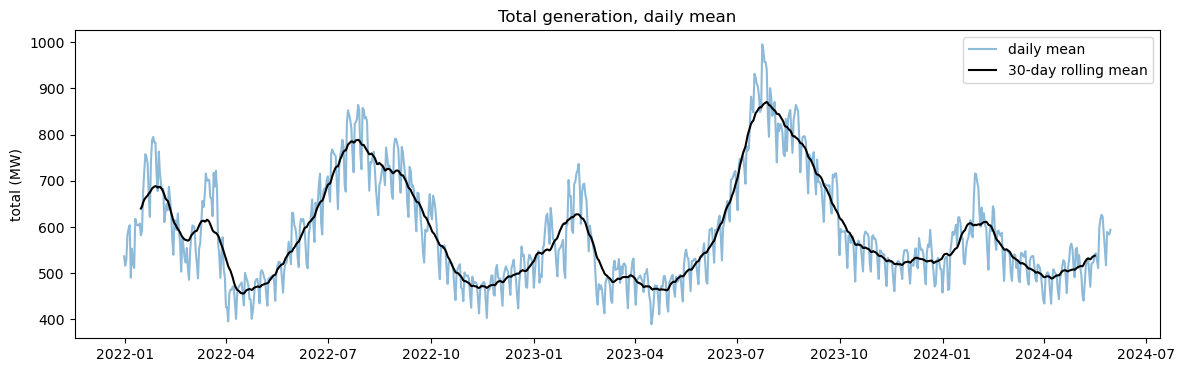

In [12]:
daily = hourly["total"].resample("D").mean()

plt.figure(figsize=(14, 4))
plt.plot(daily, alpha=0.5, label="daily mean")
plt.plot(daily.rolling(30, center=True).mean(), c="0", label="30-day rolling mean")
plt.ylabel("total (MW)")
plt.title("Total generation, daily mean")
plt.legend()
plt.show()

**Strong yearly seasonality:** Summer (Jul-Aug) averages roughly 1.6-1.7x the level of spring and late autumn, consistent with cooling demand.

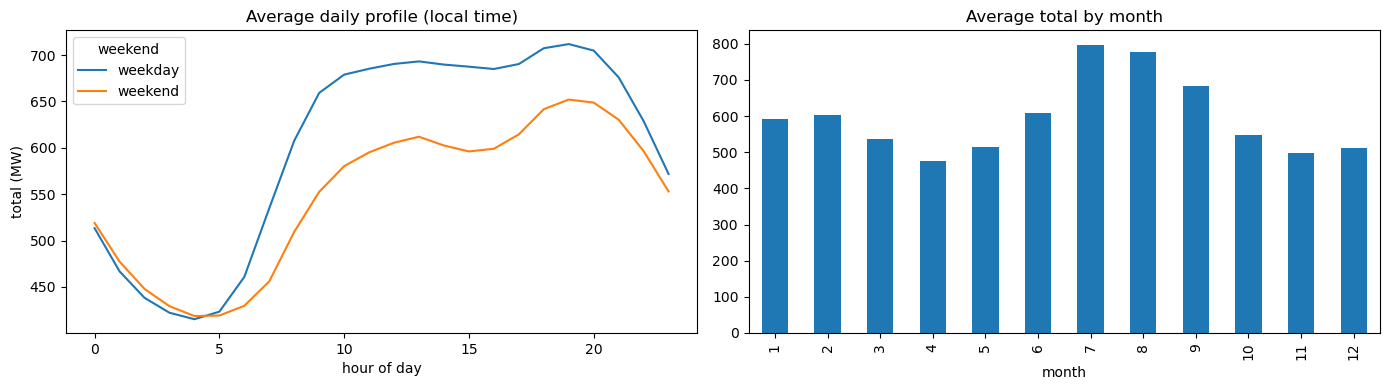

In [13]:
local = hourly.index.tz_convert("Asia/Nicosia")
prof = hourly[["total"]].assign(hour=local.hour, weekend=np.where(local.dayofweek >= 5, "weekend", "weekday"))
prof = prof.groupby(["weekend", "hour"])["total"].mean().unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
prof.plot(ax=axes[0])
axes[0].set_title("Average daily profile (local time)")
axes[0].set_xlabel("hour of day")
axes[0].set_ylabel("total (MW)")

hourly["total"].groupby(local.month).mean().plot.bar(ax=axes[1])
axes[1].set_title("Average total by month")
axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()

* Demand on the bottom around 4-5AM, then goes up towards its peek at 7PM
* Demand on weekends is slightly less.
* Difference in the demand between weekends & weekdays is roughly around 100MW
* Again, peeks are in the Jun-Sep, and minimums are in spring-autumn.

<hr>

## Features Engineering for GBM

**We will add calendar, lags, and rolling features**

Test window `horizon` is 168 hours long and is forecast in one shot, so **every lag & rolling feature must be at least 168 hours old**. Otherwise a test row would use observed values from inside the test week, which a real forecast would not have, its data leakage. Therefore all lags are 168h or more and all rolling windows are computed on the series shifted by 168h.

In [14]:
# dropping meaningless features
cols = ["oil", "wind", "pv", "biomass", "gas", "coal", "water"]
feat = df.drop(cols, axis=1)
horizon = 168

In [15]:
# 7, 14, 30 days ago
lag_list = [168, 336, 720]
for lag in lag_list:
    feat[f"total_lag_{lag}"] = feat["total"].shift(lag)

In [16]:
# rollings of [1, 7, 14, 30 days] shifted by 168 hours
window_list = [24, 168, 336, 720]
for window in window_list:
    past = feat["total"].shift(horizon)
    feat[f"rllg_mean_{window}"] = past.rolling(window).mean()
    feat[f"rllg_std_{window}"]  = past.rolling(window).std()

In [17]:
feat.index = feat.index.tz_convert("Asia/Nicosia") # index is already tz-aware UTC

# weekly/time features
feat["hour"] = local.hour
feat["dayofweek"] = local.dayofweek
feat["month"] = local.month
feat["is_weekend"] = (feat["dayofweek"] >= 5).astype(int)

In [18]:
feat = feat.drop(['timestamp'], axis=1)

In [19]:
feat.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 21143 entries, 2022-01-01 00:00:00+02:00 to 2024-05-30 23:00:00+03:00
Freq: H
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   total          21143 non-null  float64
 1   total_lag_168  20975 non-null  float64
 2   total_lag_336  20807 non-null  float64
 3   total_lag_720  20423 non-null  float64
 4   rllg_mean_24   20952 non-null  float64
 5   rllg_std_24    20952 non-null  float64
 6   rllg_mean_168  20808 non-null  float64
 7   rllg_std_168   20808 non-null  float64
 8   rllg_mean_336  20640 non-null  float64
 9   rllg_std_336   20640 non-null  float64
 10  rllg_mean_720  20256 non-null  float64
 11  rllg_std_720   20256 non-null  float64
 12  hour           21143 non-null  int32  
 13  dayofweek      21143 non-null  int32  
 14  month          21143 non-null  int32  
 15  is_weekend     21143 non-null  int32  
dtypes: float64(12), int32(4)
memory usage: 

In [20]:
display(feat.tail(10))

,total,total_lag_168,total_lag_336,total_lag_720,rllg_mean_24,rllg_std_24,rllg_mean_168,rllg_std_168,rllg_mean_336,rllg_std_336,rllg_mean_720,rllg_std_720,hour,dayofweek,month,is_weekend
2024-05-30 14:00:00+03:00,715.0,783.0,640.0,682.0,628.833333,122.170824,572.339286,115.856396,543.997024,108.845269,529.194444,101.867901,14,3,5,0
2024-05-30 15:00:00+03:00,702.0,761.0,628.0,590.0,629.916667,123.263562,573.130952,116.690417,544.389881,109.389840,529.401389,102.187200,15,3,5,0
2024-05-30 16:00:00+03:00,670.0,771.0,622.0,646.0,630.500000,123.922486,574.017857,117.626552,544.866071,110.027066,529.625000,102.539363,16,3,5,0
2024-05-30 17:00:00+03:00,675.0,734.0,623.0,638.0,631.458333,124.658832,574.678571,118.213616,545.226190,110.447946,529.841667,102.806189,17,3,5,0
2024-05-30 18:00:00+03:00,631.0,707.0,611.0,612.0,632.000000,124.970257,575.250000,118.621561,545.604167,110.784103,530.023611,103.003724,18,3,5,0
2024-05-30 19:00:00+03:00,621.0,678.0,598.0,604.0,631.833333,124.903325,575.726190,118.873742,545.895833,111.003716,530.163889,103.136478,19,3,5,0
2024-05-30 20:00:00+03:00,618.0,658.0,607.0,623.0,630.666667,124.505515,576.029762,119.019116,546.080357,111.138704,530.223611,103.198103,20,3,5,0
2024-05-30 21:00:00+03:00,620.0,644.0,593.0,600.0,629.458333,124.217194,576.333333,119.127651,546.261905,111.248960,530.306944,103.265791,21,3,5,0
2024-05-30 22:00:00+03:00,573.0,594.0,544.0,554.0,628.041667,124.428250,576.630952,119.108845,546.437500,111.277691,530.391667,103.293023,22,3,5,0
2024-05-30 23:00:00+03:00,523.0,544.0,490.0,507.0,626.625000,125.213839,576.952381,118.946413,546.616071,111.225326,530.481944,103.276448,23,3,5,0


<hr>

**WAPE score** <br>
Weighted Absolute Percentage Error: total absolute error divided by total actual values. <br>
* **MAPE** breaks when `y_true = 0`, **WAPE** doesn't
* **MAPE** gives equal weight to all observations, so small-value rows can dominate, **WAPE** is more stable

**`WAPE = 20%`** means total predicted volume is off by 20% relative to total actual volume.

In [21]:
def wape_nonzero(y_true, y_pred, eps=1e-9):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    m = (y_true != 0)
    if m.sum() == 0:
        return 0.0
    return np.sum(np.abs(y_true[m] - y_pred[m])) / (np.sum(np.abs(y_true[m])) + eps)

wape_nonzero_scorer = make_scorer(wape_nonzero, greater_is_better=False)

<hr>

## Train-Test Sets

**The test set is the last 168 hours (one week)** and the forecast is made **in one shot**: every model sees only data up to the cut-off and predicts all 168 future hours. One full week covers every hour of day and day of week once, which makes the comparison fair across the daily and weekly cycles.

In [22]:
horizon = 168 # 1 week

# cut off date = last timestamp before the test week
cutoff_date = feat.index[-horizon - 1]

train_df = feat[feat.index <= cutoff_date].copy()
test_df  = feat[feat.index > cutoff_date].copy()

print(len(train_df), len(test_df))

20975 168


**Train** set date period (UTC)

In [23]:
display(train_df.index.min())
display(train_df.index.max())

Timestamp('2022-01-01 00:00:00+0200', tz='Asia/Nicosia')

Timestamp('2024-05-23 23:00:00+0300', tz='Asia/Nicosia')

**Test** set date period (UTC)

In [24]:
display(test_df.index.min())
display(test_df.index.max())

Timestamp('2024-05-24 00:00:00+0300', tz='Asia/Nicosia')

Timestamp('2024-05-30 23:00:00+0300', tz='Asia/Nicosia')

In [25]:
# train features & target
X_train = train_df.drop(columns=['total'])
y_train = train_df["total"]

# test features & target
X_test = test_df.drop(columns=['total'])
y_test  = test_df["total"]

<hr>

## Models Forecasting

### ARIMA Baseline

Using ARIMA model for a baseline as a **stat-only method**

`(5,1,0)` was used as a statistical baseline. First differencing (`d=1`) removes the slow level drift of the series, five autoregressive lags capture short-term momentum, and no moving-average terms keep the model simple.

In [26]:
# model loading
horizon = len(y_test)

arima = ARIMA(train_df['total'].values.astype(np.float32), order=(5, 1, 0)).fit()

In [27]:
# forecasting
y_pred = arima.forecast(steps=horizon)

In [28]:
# saving predictions
y_pred = y_pred.astype(np.float32)
test_df['pred_arima'] = y_pred

In [29]:
# metrics
eps = 1e-9
mask = np.abs(y_test) > eps

mae_arima = np.mean(np.abs(y_test - y_pred))
mape_arima = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_arima = wape_nonzero(y_test, y_pred) * 100

In [30]:
# metrics dataset
metrics = pd.DataFrame([[round(mae_arima, 2), round(mape_arima, 2), round(wape_arima, 2)], 
                       ], 
                       index=["ARIMA Baseline"], 
                       columns=["MAE", "MAPE %", "WAPE %"])

In [31]:
display(metrics)

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29


### Seasonal Naive Baseline

**seasonal naive baseline:** predict `total` using the value from the **same hour one week ago** (lag 168). With a daily and weekly cycle this is much harder to beat than the 'value 60 seconds ago' baseline used for the traffic data.

In [32]:
# y_pred = lag 168
naive_pred = X_test["total_lag_168"].values
test_df['pred_naive'] = naive_pred

# metrics
mae_naive = np.mean(np.abs(y_test - naive_pred))
mape_naive = np.mean(np.abs((y_test[mask] - naive_pred[mask]) / y_test[mask])) * 100
wape_naive = wape_nonzero(y_test, naive_pred) * 100

# adding scores to the metrics dataset
metrics.loc["Seasonal Naive"] = [round(mae_naive, 2), round(mape_naive, 2), round(wape_naive, 2)]

display(metrics)

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29
Seasonal Naive,30.23,5.18,5.30


<hr>

### GBM

In [33]:
# time-series cross validation, used because regular CV is invalid
tscv = TimeSeriesSplit(n_splits=3)

# CatBoost model
catboost = CatBoostRegressor(task_type="GPU")

# parameter grid for GridSearch
param_grid = {
    "depth": [4, 6, 10],
    "learning_rate": [0.01, 0.1, 0.5],
    "l2_leaf_reg": [30, 100],
    "iterations": [6000],
    "random_strength": [0.5, 2.0],
}

grid = GridSearchCV(
    estimator=catboost,
    param_grid=param_grid,
    cv=tscv,
    scoring={"wape": wape_nonzero_scorer, "mae": "neg_mean_absolute_error"},
    refit="wape",
    verbose=2,
    n_jobs=1
)

In [34]:
%%time

MODEL_PATH = "gbm_cy.cbm"

if os.path.exists(MODEL_PATH):
    # model loading
    catboost = CatBoostRegressor()
    catboost.load_model(MODEL_PATH)
    print("loaded", MODEL_PATH)
else:
    t0 = time.perf_counter()
    grid.fit(X_train, y_train, early_stopping_rounds=300, verbose=6000)
    print(f"grid search took {(time.perf_counter() - t0) / 60:.1f} min")
    print("best params:", grid.best_params_)
    print("best CV WAPE:", round(-grid.best_score_ * 100, 2), "%")

    # trained model parameters
    catboost = grid.best_estimator_

    # saving model
    catboost.save_model(MODEL_PATH)

loaded gbm_cy.cbm
CPU times: total: 109 ms
Wall time: 16 ms


```
...
...
5999:	learn: 8.9518543	total: 2m 21s	remaining: 0us
[CV] END depth=10, iterations=6000, l2_leaf_reg=100, learning_rate=0.5, random_strength=2.0; total time= 2.4min
0:	learn: 157.0359151	total: 7.86ms	remaining: 47.2s
5999:	learn: 35.2042134	total: 46.1s	remaining: 0us

grid search took 141.9 min
best params: {'depth': 4, 'iterations': 6000, 'l2_leaf_reg': 100, 'learning_rate': 0.01, 'random_strength': 0.5}
best CV WAPE: 9.06 %

CPU times: total: 2h 49min 7s
Wall time: 2h 21min 55s
```

In [35]:
# model parameters
catboost.get_params()

{'random_strength': 0.5,
 'od_wait': 300,
 'od_type': 'Iter',
 'verbose': 6000,
 'iterations': 6000,
 'loss_function': 'RMSE',
 'l2_leaf_reg': 100,
 'task_type': 'GPU',
 'depth': 4,
 'learning_rate': 0.01}

In [36]:
# prediction on test set
y_pred = catboost.predict(X_test)
test_df["pred_gbm"] = y_pred

In [37]:
# metrics
mae_gbm = np.mean(np.abs(y_test - y_pred))
mape_gbm = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_gbm = wape_nonzero(y_test, y_pred) * 100

metrics.loc["GBM (Catboost)"] = [round(mae_gbm, 2), round(mape_gbm, 2), round(wape_gbm, 2)]

display(metrics)

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29
Seasonal Naive,30.23,5.18,5.30
GBM (Catboost),21.97,3.80,3.85


`total_lag_168` clearly dominates here with around 63% of importance, second place is `month` with around 10%.

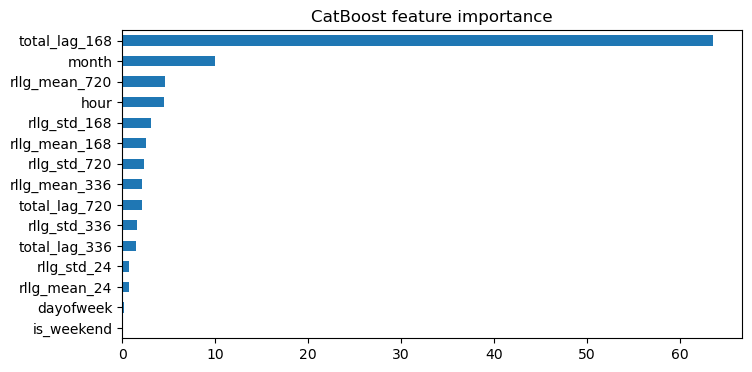

In [38]:
# gbm feature importance
imp = pd.Series(catboost.get_feature_importance(), index=X_train.columns).sort_values()
imp.plot.barh(figsize=(8, 4), title="CatBoost feature importance")
plt.show()

<hr>

## Foundation Models: Three Architectural Families


### TimesFM (Google): Patch-based
* Patch = a small chunk of consecutive time points grouped together (e.g. 32 points).
* Series is sliced into patches, each patch is treated as one "token", similar to how Vision Transformers split an image into patches.
* **Raw numeric values** are kept inside each patch, they **are not converted into words or symbols.**
* Decoder-only transformer that predicts the next patch.

### Chronos (Amazon): from tokenization to patching
**Original Chronos (2024): Tokenization/Quantization**
* **Turns continuous numbers into discrete tokens**, then treats forecasting as a language-modeling problem.
* Scale the series -> quantize it -> bin real values into a fixed vocabulary (e.g. value 3.7 -> token #142).
* A standard language model (T5 architecture) is trained with cross-entropy loss, **exactly like next-word prediction**.
* Downside: quantization loses precision, since every value is rounded to its bin.

**Chronos-2 (2025): the version used in this project, no tokenization**
* **Does not quantize values into tokens.** Like TimesFM, it is **patch-based**.
* Each series is standardized (mean/std) and passed through an **arcsinh transform** to reduce the effect of outliers. It is then split into patches and each patch is embedded by a small neural network.
* **Encoder-only** transformer (based on the T5 encoder) with two types of attention:
  * **time attention** across patches of the same series,
  * **group attention** across related series, which lets it use **multiple series and covariates** (e.g. temperature).
* Outputs **21 quantiles directly** (probabilistic forecast), trained with **quantile loss** instead of cross-entropy.
* Context length up to **8192** points, **120M parameters**.

### TiRex (NXAI): xLSTM-based

* Not transformer, **built on xLSTM** (an enhanced LSTM) instead.
* Transformers dominate zero-shot forecasting but often underperform recurrent models (LSTMs) on time series, while classic LSTMs **lack strong in-context learning**. xLSTM aims to combine both strengths.
* State-tracking: the model **continuously updates a hidden state** over time, which helps on long forecast horizons (transformers lack this).
* Still uses patching, but runs it through a recurrent backbone instead of attention.
* Only **35M parameters** (much smaller than TimesFM2.0 at 500M or Chronos at 200M), yet should achieve state-of-the-art zero-shot results.

### TimesFM

In [39]:
# model loading
timesfm_model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")

In [40]:
# predict horizon & max_context length
horizon = len(y_test)
max_context = len(y_train)

In [41]:
max_context = 16128 # historical context, max_context+max_horizon must be less than < 16384

# model configure
timesfm_model.compile(
    timesfm.ForecastConfig(
        max_context=max_context, 
        max_horizon=256, # ceiling of forecasting horizon (> 168)
        normalize_inputs=True,
        use_continuous_quantile_head=True,
        force_flip_invariance=True,
        infer_is_positive=True, # generation can not be negative
        fix_quantile_crossing=True,
    )
)

In [42]:
# context (train set) for model to look on
context = train_df["total"].values.astype(np.float32)

# forecasting
point_forecast, quantile_forecast = timesfm_model.forecast(
    horizon=horizon,
    inputs=[context], # single series -> list with one array
)

In [43]:
# predicted values
y_pred = point_forecast[0]
test_df['pred_timesfm'] = y_pred

In [44]:
# metrics
mae_timesfm = np.mean(np.abs(y_test - y_pred))
mape_timesfm = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_timesfm = wape_nonzero(y_test, y_pred) * 100

metrics.loc["TimesFM"] = [round(mae_timesfm, 2), round(mape_timesfm, 2), round(wape_timesfm, 2)]

In [45]:
display(metrics)

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29
Seasonal Naive,30.23,5.18,5.30
GBM (Catboost),21.97,3.80,3.85
TimesFM,22.57,3.84,3.96


In [46]:
display(test_df.head())

,total,total_lag_168,total_lag_336,total_lag_720,rllg_mean_24,rllg_std_24,rllg_mean_168,rllg_std_168,rllg_mean_336,rllg_std_336,rllg_mean_720,rllg_std_720,hour,dayofweek,month,is_weekend,pred_arima,pred_naive,pred_gbm,pred_timesfm
2024-05-24 00:00:00+03:00,495.0,446.0,443.0,438.0,540.041667,101.740283,516.297619,93.881793,502.747024,90.871362,514.370833,93.236251,0,4,5,0,509.196808,446.0,453.063732,503.410889
2024-05-24 01:00:00+03:00,458.0,416.0,406.0,406.0,540.375000,101.301020,516.357143,93.814589,502.720238,90.895671,514.427778,93.163504,1,4,5,0,490.170807,416.0,421.799294,467.472656
2024-05-24 02:00:00+03:00,434.0,398.0,384.0,388.0,540.791667,100.665602,516.440476,93.702466,502.708333,90.909163,514.486111,93.077277,2,4,5,0,482.803467,398.0,398.146000,444.230652
2024-05-24 03:00:00+03:00,425.0,384.0,373.0,377.0,541.041667,100.250330,516.505952,93.605427,502.687500,90.935637,514.536111,92.997353,3,4,5,0,486.607361,384.0,396.278428,428.896423
2024-05-24 04:00:00+03:00,424.0,384.0,368.0,374.0,541.375000,99.689436,516.601190,93.461455,502.678571,90.947176,514.587500,92.914833,4,4,5,0,497.795349,384.0,395.804269,422.908630


<hr>

### Chronos

Pandas DFs to AutoGluon TimeSeriesDF

In [47]:
train_ag = train_df[["total"]].copy() # Chronos only needs the target here
train_ag["item_id"] = "total"
train_ag["dt"] = train_ag.index.tz_convert("UTC").tz_localize(None) # tz-naive UTC timestamps

train_data = TimeSeriesDataFrame.from_data_frame(
    train_ag,
    id_column="item_id",
    timestamp_column="dt",)

<hr>

In [48]:
# model loading (zero-shot)
model = TimeSeriesPredictor(
    prediction_length=horizon,
    target="total",
    freq="h",
).fit(
    train_data,
    hyperparameters={
        "Chronos2": {"context_length": None},},
    presets="chronos2",
)

Frequency 'h' stored as 'H'
Beginning AutoGluon training...
AutoGluon will save models to 'C:\Users\whois\Desktop\New folder\unic\COMP494 Final Project (Thesis)\AutogluonModels\ag-20261106_100619'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.11.7
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.5.1+cu121
CUDA Version:       12.1
GPU Memory:         GPU 0: 7.13/8.00 GB
Total GPU Memory:   Free: 7.13 GB, Allocated: 0.87 GB, Total: 8.00 GB
GPU Count:          1
Memory Avail:       10.84 GB / 31.19 GB (34.8%)
Disk Space Avail:   71.17 GB / 464.77 GB (15.3%)
Setting presets to: chronos2

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WQL,
 'freq': 'H',
 'hyperparameters': {'Chronos2': {'context_length': None}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 168,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.

In [49]:
pred = model.predict(train_data,
                     model="Chronos2",)

In [50]:
# saving predictions
y_pred = pred['mean'].values.astype(np.float32)
test_df['pred_chronos'] = y_pred

In [51]:
# metrics
mae_chronos = np.mean(np.abs(y_test - y_pred))
mape_chronos = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_chronos = wape_nonzero(y_test, y_pred) * 100

metrics.loc["Chronos"] = [round(mae_chronos, 2), round(mape_chronos, 2), round(wape_chronos, 2)]

In [52]:
display(metrics)

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29
Seasonal Naive,30.23,5.18,5.30
GBM (Catboost),21.97,3.80,3.85
TimesFM,22.57,3.84,3.96
Chronos,28.80,4.99,5.05


<hr>

### Chronos Fine-Tuned

In [53]:
print(torch.__version__)
print(torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.5.1+cu121
True
NVIDIA GeForce RTX 4060


LoRA fine-tuning on a single long series. If a tuned model is already saved it is loaded instead of re-trained.

In [54]:
FT_PATH = "saved_models/chronos2_lora_cy"

if os.path.exists(FT_PATH):
    # loading tuned Chronos model
    model_ft = TimeSeriesPredictor.load(FT_PATH)
else: # fine-tuning and saving
    t0 = time.perf_counter()
    model_ft = TimeSeriesPredictor(
        prediction_length=horizon,
        target="total",
        freq="h",
        path=FT_PATH,
        verbosity=3, # prints training and validation loss
    ).fit(
        train_data,
        skip_model_selection=False, # creates validation window
        num_val_windows=1,
        hyperparameters={
            "Chronos2": {"fine_tune": True, 
                         "fine_tune_mode": "lora", 
                         "ag_args": {"name_suffix": "FineTunedCy"},
                         "fine_tune_context_length": 4096,
                         "eval_during_fine_tune": True}}, # keeps the best checkpoint by validation loss
        presets="chronos2",
    )
    print(f"fine-tuning took {time.perf_counter() - t0:.0f} s")

Loading predictor from path C:\Users\whois\Desktop\New folder\unic\COMP494 Final Project (Thesis)\saved_models\chronos2_lora_cy


**21 minutes for fine-tuning Chronos**

In [55]:
# prediction
pred = model_ft.predict(train_data,
                        model="Chronos2FineTunedCy",)

In [56]:
# saving predictions
y_pred = pred['mean'].values.astype(np.float32)
test_df['pred_chronos_ft'] = y_pred

In [57]:
# metrics
mae_chronos_ft = np.mean(np.abs(y_test - y_pred))
mape_chronos_ft = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_chronos_ft = wape_nonzero(y_test, y_pred) * 100

metrics.loc["Chronos Fine-Tuned"] = [round(mae_chronos_ft, 2), round(mape_chronos_ft, 2), round(wape_chronos_ft, 2)]

_We use **LoRA (Low-Rank Adaptation)**: the original model weights are frozen and only small extra matrices are trained (rank 8, inside the attention layers and the output layer). This is much faster, uses less GPU memory, and makes it harder to "destroy" what the model learned in pretraining._

**Training data**
* At every step, the trainer cuts **random windows** from anywhere in the training series: a context part (the input) and the next `prediction_length` values (the target to predict).
* Each step uses a batch of 32 windows (AutoGluon `fine_tune_batch_size=32` by default). Over 1000 steps that is ~32,000 windows taken from **a single series**, so the same history is seen many times. That is the main risk of overfitting here.

**Validation and checkpoint selection**
* The last `prediction_length` values of the training set are held out as a **validation window**, which is the period right before the test set.
* Every 100 steps the model is evaluated on that window (`eval_loss`), and at the end the **checkpoint with the lowest validation loss is kept**, not simply the last one.
* With the default settings (no validation), the model from step 1000 (last one) was used regardless of quality, and it was slightly worse than zero-shot.

**Training log**
* `loss` is the training error on the random windows; `eval_loss` is the error on the validation window.
* Both are **quantile losses on the model's internal scaled values**, not MAE in MW or cars. They are only useful for comparing steps with each other.
* If `loss` keeps falling while `eval_loss` rises, the model is memorising the training history instead of learning patterns that generalise. That is overfitting.

**Settings**
| parameter | value | meaning |
|---|---|---|
| `fine_tune_mode` | lora | train small adapters only |
| `fine_tune_batch_size` | 32 (default) | windows per step |
| `fine_tune_context_length` | 4096 | max input length during training |
| `eval_during_fine_tune` | True | validate every 100 steps, keep the best |

**Limitation**
* AutoGluon recommends fine-tuning on many series (>100). So, there is only **one series**, so there is little new information to learn beyond what zero-shot Chronos-2 already captures from the context.
* Fine-tuning took **21 minutes** on an RTX 4060, versus a few seconds for zero-shot prediction.

<hr>

### TiRex

In [58]:
model = load_model("NX-AI/TiRex", device="cuda")

In [59]:
# single series shape
context = torch.tensor(context).unsqueeze(0)

# TiRex returns quantiles & mean
quantiles, mean = model.forecast(context=context, prediction_length=horizon)

# make sure its plain numpy array
if torch.is_tensor(mean):
    mean = mean.cpu().numpy()
else: np.asarray(mean)

In [60]:
# predictions
y_pred = mean[0]
test_df['pred_tirex'] = y_pred

In [61]:
# metrics
mae_tirex  = np.mean(np.abs(y_test - y_pred))
mape_tirex = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_tirex = wape_nonzero(y_test, y_pred) * 100

metrics.loc["TiRex"] = [round(mae_tirex, 2), round(mape_tirex, 2), round(wape_tirex, 2)]

In [62]:
# final metrics dataset
display(metrics.sort_values('MAE', ascending=False))

,MAE,MAPE %,WAPE %
ARIMA Baseline,98.57,17.17,17.29
Chronos Fine-Tuned,30.95,5.32,5.43
Seasonal Naive,30.23,5.18,5.30
Chronos,28.80,4.99,5.05
TimesFM,22.57,3.84,3.96
GBM (Catboost),21.97,3.80,3.85
TiRex,12.90,2.20,2.26


<hr>

## Forecasting Analysis

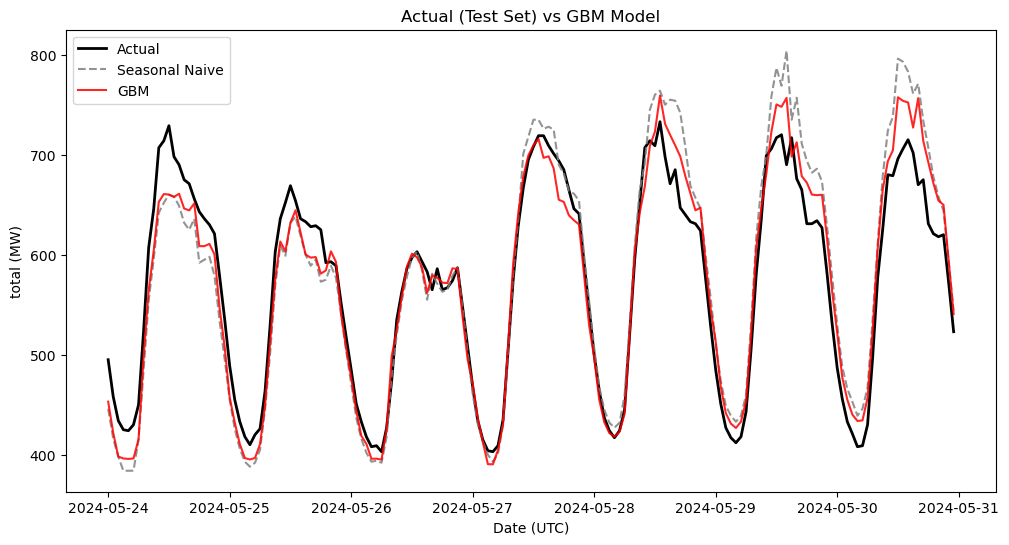

In [63]:
plt.figure(figsize=(12, 6))
plt.plot(test_df.index, y_test, label="Actual", c="0", linewidth=2)
plt.plot(test_df.index, test_df["pred_naive"], label="Seasonal Naive", c="gray", alpha=0.85, linestyle="--")
plt.plot(test_df.index, test_df["pred_gbm"], label="GBM", c="red", alpha=0.85)
plt.title("Actual (Test Set) vs GBM Model")
plt.xlabel("Date (UTC)")
plt.ylabel("total (MW)")
plt.legend()
plt.show()

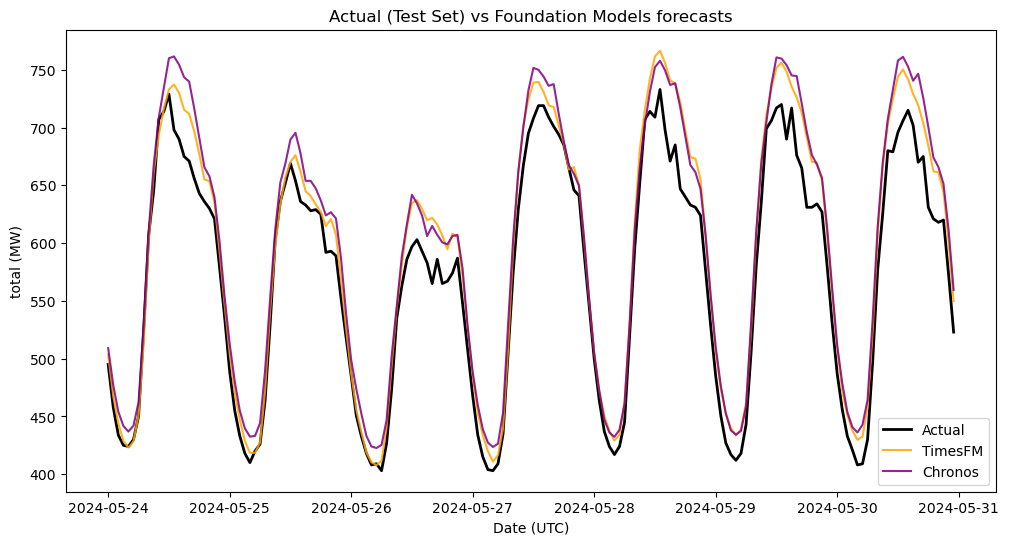

In [64]:
plt.figure(figsize=(12, 6))
plt.plot(test_df.index, y_test, label="Actual", c="0", linewidth=2)
plt.plot(test_df.index, test_df["pred_timesfm"], label="TimesFM", c="orange", alpha=0.85)
plt.plot(test_df.index, test_df["pred_chronos"], label="Chronos", c="purple", alpha=0.85)
plt.title("Actual (Test Set) vs Foundation Models forecasts")
plt.xlabel("Date (UTC)")
plt.ylabel("total (MW)")
plt.legend()
plt.show()

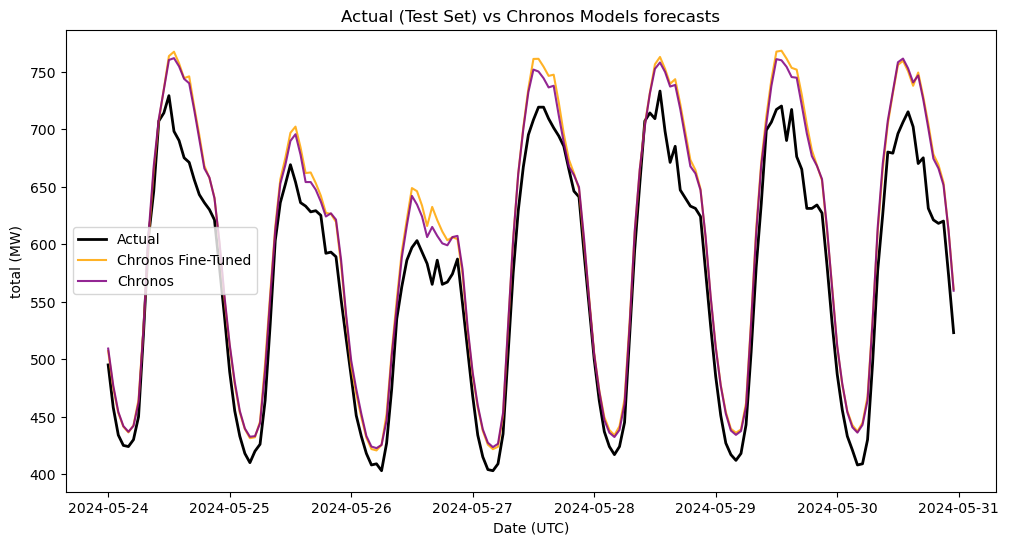

In [65]:
plt.figure(figsize=(12, 6))
plt.plot(test_df.index, y_test, label="Actual", c="0", linewidth=2)
plt.plot(test_df.index, test_df["pred_chronos_ft"], label="Chronos Fine-Tuned", c="orange", alpha=0.85)
plt.plot(test_df.index, test_df["pred_chronos"], label="Chronos", c="purple", alpha=0.85)
plt.title("Actual (Test Set) vs Chronos Models forecasts")
plt.xlabel("Date (UTC)")
plt.ylabel("total (MW)")
plt.legend()
plt.show()

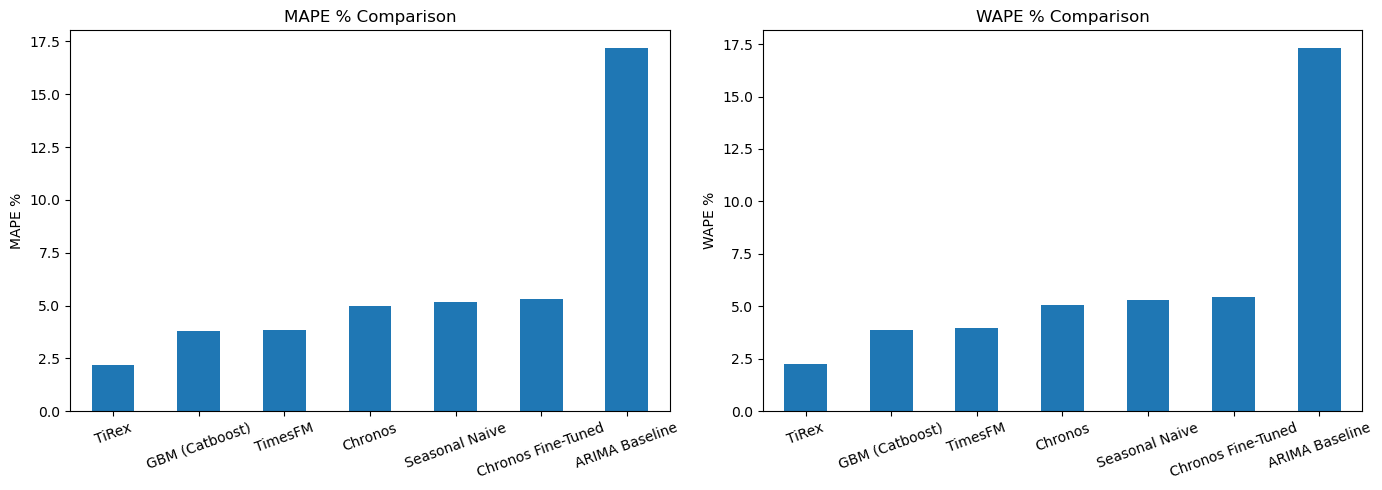

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["MAPE %", "WAPE %"]):
    metrics[col].dropna().sort_values().plot(kind="bar", ax=ax)
    ax.set_ylabel(col)
    ax.set_title(f"{col} Comparison")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

<hr>

# Results

* **Baseline check:** does each model beat the **seasonal naive** baseline (same hour one week ago)? On strongly seasonal data this baseline is hard to beat, and the gap to it is the real measure of value added. TiRex reduces MAE by **~57%** vs seasonal naive, CatBoost by ~27% and TimesFM by ~25%. Zero-shot Chronos is only ~5% better, and **fine-tuned Chronos is slightly worse than the baseline** (WAPE 5.43% vs 5.30%). ARIMA (5,1,0) has no seasonal component and is far behind.
* **Earlier check-run observation:** CatBoost reaches **3.85%** vs seasonal naive 5.3%, so it does beat the weekly pattern. Exogenous features (temperature, public holidays) are still the natural next step, since peak demand depends on weather that no model here can see.
* **Foundation models vs GBM:** in the traffic experiment (exp1), foundation models produced smooth forecasts and missed short-term spikes. On energy data the signal is a smooth daily/weekly cycle. **TiRex clearly beats the GBM**, and **TimesFM matches it** (22.57 vs 21.97 MAE) with no feature engineering. Both Chronos models capture the **night trough** well but **overshoot the daytime peaks** by ~30-50 MW (see the forecast plots).
* **Effort vs accuracy:** GBM needs feature engineering (calendar, lags >= 168h) and a hyperparameter search; foundation models need none, only a context window. TiRex gives the best result with zero training.
* **Fine-tuning:** LoRA fine-tuning made Chronos **worse** than zero-shot (MAE 30.95 vs 28.80) and took ~20 minutes vs a few seconds for zero-shot. This is in line with AutoGluon's recommendation (>100 series): here there is still only one series, but with ~21k points of history instead of ~7k (exp1 vs exp2 data points), so the adapter mostly re-learns the same history.
* **Limitations:** a single 168h test window (one week in late May 2024) is a small sample; the data has only ~2.4 years, so the yearly cycle is seen twice. A rolling-origin evaluation over several weeks would make the conclusions more robust.



In [68]:
display(metrics.sort_values("MAE"))

,MAE,MAPE %,WAPE %
TiRex,12.90,2.20,2.26
GBM (Catboost),21.97,3.80,3.85
TimesFM,22.57,3.84,3.96
Chronos,28.80,4.99,5.05
Seasonal Naive,30.23,5.18,5.30
Chronos Fine-Tuned,30.95,5.32,5.43
ARIMA Baseline,98.57,17.17,17.29


### Why TiRex wins on Cyprus

* **Clean, strongly seasonal data.** MAPE is only 2 to 5%, so the signal is mostly a stable daily and weekly cycle. The importance plot backs this up: `total_lag_168` dominates, so "same hour last week" does most of the work. Models that preserve a seasonal pattern precisely do best here.
* **TiRex is built for this.** It's an xLSTM-based model with explicit state tracking, designed to hold onto periodic structure over long horizons. It also used the **full training history** (21k hours, two previous Mays) as context, while TimesFM saw 16k hours and Chronos-2 only **8192 hours (~11 months)**, so Chronos-2 never sees the same season last year. The ranking follows the context length: TiRex > TimesFM > Chronos.
* **CatBoost gets explicit calendar knowledge.** It has hour, month, the 168h lag and rolling stats at 168/336/720h. The foundation models only see the raw series, so CatBoost starts with the seasonal structure handed to it. That is why it matches TimesFM, but without TiRex's long context it does not reach TiRex.


### Why that flips in Romania

* The car count data is noisy, high-frequency and has no clean periodicity (MAPE of 23 to 43%). There's little structure for hand-built lags to exploit, and the pretrained priors of Chronos help more: **fine-tuned Chronos is best (MAE 1.67)**, followed by zero-shot Chronos (1.73). TiRex and TimesFM are close behind (2.21 and 2.26). CatBoost drops to 2.58, roughly ARIMA level, after the raw timestamp `dt` was removed from its features.
* Fine-tuning helps slightly in Romania (1.73 -> 1.67) but hurts in Cyprus (28.80 -> 30.95): with a single series, its effect depends on the data and is small either way.